# 03 – Baseline Models
Logistic Regression and Decision Tree, binary and multi-class.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from src.config import RANDOM_STATE         

TRAIN_PATH = "../data/processed/train.parquet"
TEST_PATH  = "../data/processed/test.parquet"

In [2]:
train = pd.read_parquet(TRAIN_PATH)
test  = pd.read_parquet(TEST_PATH)
print(train.shape, test.shape)

(341633, 64) (85409, 64)


In [3]:
LABEL_COLS = ["label_multi", "label_binary"]

X_train = train.drop(columns=LABEL_COLS)
X_test  = test.drop(columns=LABEL_COLS)

y_train_bin   = train["label_binary"]
y_test_bin    = test["label_binary"]
y_train_multi = train["label_multi"]
y_test_multi  = test["label_multi"]

print(X_train.shape, X_test.shape)

(341633, 62) (85409, 62)


In [4]:
print(y_train_bin.value_counts())
print(y_train_multi.value_counts())

label_binary
0    186996
1    154637
Name: count, dtype: int64
label_multi
Benign    186996
Dos       101205
DDoS       40215
Bot         7165
Prob        6052
Name: count, dtype: int64


In [5]:
import time
from sklearn.metrics import f1_score, accuracy_score, classification_report

In [6]:
def evaluate(model, name, task, X_tr, y_tr, X_te, y_te):
    # 1) train and measure time
    t0 = time.perf_counter()
    model.fit(X_tr,y_tr)
    train_time = time.perf_counter() - t0

    # 2) predict and measure time
    t0 = time.perf_counter()
    y_pred = model.predict(X_te)
    predict_time = time.perf_counter() - t0
    predict_ms = predict_time / len(X_te) * 1000 #converts seconds to ms

    # 3) show the detailed report
    print(f"=== {name} | {task} ===")
    print(classification_report(y_te,y_pred,digits=4))

    # 4) return one row for results.csv
    return{
        "model":name,
        "task":task,
        "imbalance":"none",
        "macro_f1":f1_score(y_te,y_pred,average="macro"),
        "accuracy":accuracy_score(y_te,y_pred),
        "train_time_s":round(train_time,2),
        "predict_ms_per_flow":round(predict_ms,5),
        "notes":"",

    }


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [8]:
result = [] # we collect one dictionary per model here

lr_bin = Pipeline([
    ("scaler",StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

row = evaluate(lr_bin, "LogisticRegression","binary",
               X_train,y_train_bin,X_test,y_test_bin)
result.append(row)
row


=== LogisticRegression | binary ===
              precision    recall  f1-score   support

           0     0.9743    0.8606    0.9140     46749
           1     0.8523    0.9726    0.9085     38660

    accuracy                         0.9113     85409
   macro avg     0.9133    0.9166    0.9112     85409
weighted avg     0.9191    0.9113    0.9115     85409



{'model': 'LogisticRegression',
 'task': 'binary',
 'imbalance': 'none',
 'macro_f1': 0.9112246787869878,
 'accuracy': 0.9113091126227915,
 'train_time_s': 12.22,
 'predict_ms_per_flow': 0.0004,
 'notes': ''}

In [9]:
lr_multi = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

row = evaluate(lr_multi, "LogisticRegression", "multiclass",
               X_train, y_train_multi, X_test, y_test_multi)
result.append(row)
row

=== LogisticRegression | multiclass ===


C:\Users\YasarAdmin\Desktop\iotshield-sdn-ids\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\YasarAdmin\Desktop\iotshield-sdn-ids\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\YasarAdmin\Desktop\iotshield-sdn-ids\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

              precision    recall  f1-score   support

      Benign     0.9375    0.8910    0.9136     46749
         Bot     0.0000    0.0000    0.0000      1792
        DDoS     0.5018    0.8870    0.6410     10054
         Dos     0.9598    0.8560    0.9049     25301
        Prob     0.6495    0.2756    0.3870      1513

    accuracy                         0.8506     85409
   macro avg     0.6097    0.5819    0.5693     85409
weighted avg     0.8680    0.8506    0.8505     85409



{'model': 'LogisticRegression',
 'task': 'multiclass',
 'imbalance': 'none',
 'macro_f1': 0.5693111445283946,
 'accuracy': 0.8505543912234074,
 'train_time_s': 28.5,
 'predict_ms_per_flow': 0.00052,
 'notes': ''}

In [10]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train_multi,
    test_size=0.2,
    stratify=y_train_multi,
    random_state=RANDOM_STATE
)

lr_multi_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )),
])

row_balanced = evaluate(
    lr_multi_balanced,
    "LogisticRegression",
    "multiclass",
    X_fit, y_fit, X_val, y_val
)

row_balanced["imbalance"] = "balanced"
row_balanced

=== LogisticRegression | multiclass ===
              precision    recall  f1-score   support

      Benign     0.9903    0.8265    0.9010     37400
         Bot     0.1454    0.7202    0.2419      1433
        DDoS     0.4377    0.4933    0.4638      8043
         Dos     0.9494    0.8627    0.9039     20241
        Prob     0.2803    0.5926    0.3806      1210

    accuracy                         0.7916     68327
   macro avg     0.5606    0.6990    0.5783     68327
weighted avg     0.8828    0.7916    0.8274     68327



{'model': 'LogisticRegression',
 'task': 'multiclass',
 'imbalance': 'balanced',
 'macro_f1': 0.5782572557479517,
 'accuracy': 0.7916050755923719,
 'train_time_s': 31.83,
 'predict_ms_per_flow': 0.00043,
 'notes': ''}

In [11]:
from sklearn.tree import DecisionTreeClassifier

dt_multi_val = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

row_dt_val = evaluate(
    dt_multi_val,
    "DecisionTree",
    "multiclass",
    X_fit, y_fit, X_val, y_val
)

row_dt_val


=== DecisionTree | multiclass ===
              precision    recall  f1-score   support

      Benign     0.9165    0.9163    0.9164     37400
         Bot     0.2848    0.3001    0.2922      1433
        DDoS     0.5569    0.5523    0.5546      8043
         Dos     0.9086    0.9086    0.9086     20241
        Prob     0.5025    0.5017    0.5021      1210

    accuracy                         0.8509     68327
   macro avg     0.6338    0.6358    0.6348     68327
weighted avg     0.8512    0.8509    0.8511     68327



{'model': 'DecisionTree',
 'task': 'multiclass',
 'imbalance': 'none',
 'macro_f1': 0.6347676385348657,
 'accuracy': 0.8508934974461048,
 'train_time_s': 6.68,
 'predict_ms_per_flow': 0.00037,
 'notes': ''}

In [12]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "max_depth": [10, 20, 30, 40, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"]
}

dt_search = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=20,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=2
)

dt_search.fit(X_fit, y_fit)

print("Best parameters:", dt_search.best_params_)
print("Best CV Macro F1:", dt_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters: {'min_samples_split': 20, 'min_samples_leaf': 10, 'max_depth': 40, 'criterion': 'entropy', 'class_weight': None}
Best CV Macro F1: 0.6664692327971992


In [13]:
dt_multi_optimized = dt_search.best_estimator_

row_dt_optimized = evaluate(
    dt_multi_optimized,
    "DecisionTree",
    "multiclass",
    X_fit, y_fit, X_val, y_val
)

row_dt_optimized

=== DecisionTree | multiclass ===
              precision    recall  f1-score   support

      Benign     0.9246    0.9265    0.9255     37400
         Bot     0.3298    0.2394    0.2774      1433
        DDoS     0.5738    0.6884    0.6259      8043
         Dos     0.9451    0.9058    0.9250     20241
        Prob     0.7602    0.4769    0.5861      1210

    accuracy                         0.8700     68327
   macro avg     0.7067    0.6474    0.6680     68327
weighted avg     0.8740    0.8700    0.8705     68327



{'model': 'DecisionTree',
 'task': 'multiclass',
 'imbalance': 'none',
 'macro_f1': 0.6679948031609697,
 'accuracy': 0.869978193100824,
 'train_time_s': 5.93,
 'predict_ms_per_flow': 0.00034,
 'notes': ''}

In [14]:
param_dist_v2 = {
    "max_depth": [25, 30, 35, 40, 45, 50, None],
    "min_samples_split": [10, 15, 20, 25, 30],
    "min_samples_leaf": [5, 8, 10, 12, 15, 20],
    "criterion": ["entropy", "log_loss"],
    "class_weight": [
        None,
        "balanced",
        {"Benign": 1, "Bot": 2, "DDoS": 1, "Dos": 1, "Prob": 2},
        {"Benign": 1, "Bot": 3, "DDoS": 1, "Dos": 1, "Prob": 2},
        {"Benign": 1, "Bot": 5, "DDoS": 1, "Dos": 1, "Prob": 3}
    ]
}

dt_search_v2 = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_distributions=param_dist_v2,
    n_iter=40,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=2
)

dt_search_v2.fit(X_fit, y_fit)

print("Best parameters:", dt_search_v2.best_params_)
print("Best CV Macro F1:", dt_search_v2.best_score_)

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Best parameters: {'min_samples_split': 10, 'min_samples_leaf': 20, 'max_depth': 25, 'criterion': 'entropy', 'class_weight': {'Benign': 1, 'Bot': 2, 'DDoS': 1, 'Dos': 1, 'Prob': 2}}
Best CV Macro F1: 0.6746612654473587


In [15]:
dt_multi_optimized_v2 = dt_search_v2.best_estimator_

row_dt_optimized_v2 = evaluate(
    dt_multi_optimized_v2,
    "DecisionTree",
    "multiclass",
    X_fit, y_fit, X_val, y_val
)

row_dt_optimized_v2

=== DecisionTree | multiclass ===
              precision    recall  f1-score   support

      Benign     0.9371    0.9224    0.9297     37400
         Bot     0.2804    0.4348    0.3409      1433
        DDoS     0.5893    0.6560    0.6209      8043
         Dos     0.9523    0.9039    0.9275     20241
        Prob     0.6087    0.5669    0.5871      1210

    accuracy                         0.8690     68327
   macro avg     0.6736    0.6968    0.6812     68327
weighted avg     0.8811    0.8690    0.8743     68327



{'model': 'DecisionTree',
 'task': 'multiclass',
 'imbalance': 'none',
 'macro_f1': 0.6812010403885334,
 'accuracy': 0.8690415209214513,
 'train_time_s': 6.22,
 'predict_ms_per_flow': 0.00032,
 'notes': ''}

In [16]:
row_dt_optimized_v2["imbalance"] = "custom_class_weight"
row_dt_optimized_v2["notes"] = "Tuned Decision Tree V2 - validation"

In [17]:
dt_bin = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

row = evaluate(
    dt_bin,
    "DecisionTree",
    "binary",
    X_train, y_train_bin, X_test, y_test_bin
)

result.append(row)
row

=== DecisionTree | binary ===
              precision    recall  f1-score   support

           0     0.9184    0.9192    0.9188     46749
           1     0.9022    0.9013    0.9017     38660

    accuracy                         0.9111     85409
   macro avg     0.9103    0.9102    0.9103     85409
weighted avg     0.9111    0.9111    0.9111     85409



{'model': 'DecisionTree',
 'task': 'binary',
 'imbalance': 'none',
 'macro_f1': 0.9102506221621641,
 'accuracy': 0.9110632368954091,
 'train_time_s': 9.26,
 'predict_ms_per_flow': 0.00038,
 'notes': ''}

In [18]:
dt_multi_final = DecisionTreeClassifier(
    **dt_search_v2.best_params_,
    random_state=RANDOM_STATE
)

row_dt_final = evaluate(
    dt_multi_final,
    "DecisionTree",
    "multiclass",
    X_train, y_train_multi, X_test, y_test_multi
)

row_dt_final["imbalance"] = "custom_class_weight"
row_dt_final["notes"] = "Optimized with RandomizedSearchCV"

result.append(row_dt_final)
row_dt_final

=== DecisionTree | multiclass ===
              precision    recall  f1-score   support

      Benign     0.9366    0.9241    0.9303     46749
         Bot     0.2835    0.4448    0.3463      1792
        DDoS     0.5957    0.6517    0.6224     10054
         Dos     0.9534    0.9055    0.9288     25301
        Prob     0.5921    0.5631    0.5772      1513

    accuracy                         0.8701     85409
   macro avg     0.6722    0.6978    0.6810     85409
weighted avg     0.8816    0.8701    0.8751     85409



{'model': 'DecisionTree',
 'task': 'multiclass',
 'imbalance': 'custom_class_weight',
 'macro_f1': 0.681023716197683,
 'accuracy': 0.8701073657342903,
 'train_time_s': 8.03,
 'predict_ms_per_flow': 0.0003,
 'notes': 'Optimized with RandomizedSearchCV'}

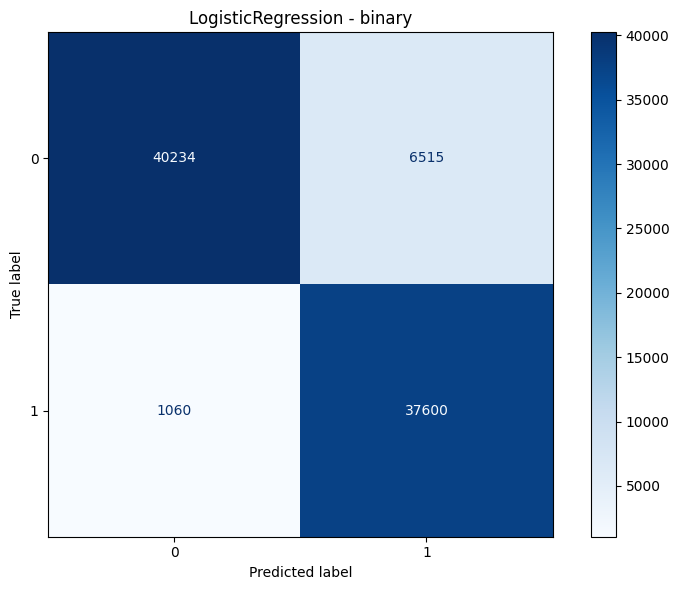

Saved: ..\reports\figures\cm_LogisticRegression_binary.png


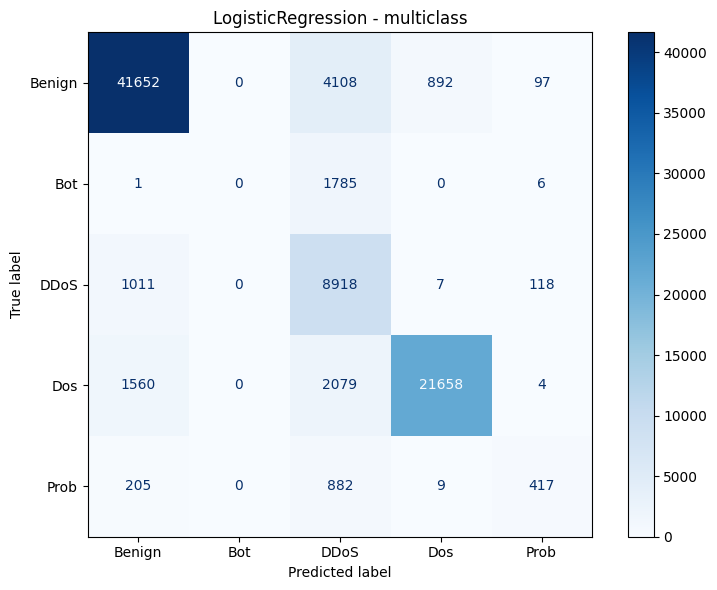

Saved: ..\reports\figures\cm_LogisticRegression_multiclass.png


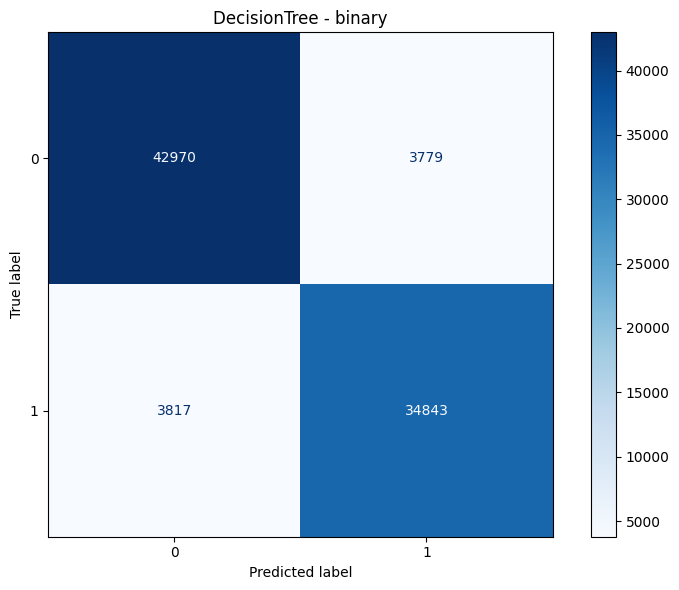

Saved: ..\reports\figures\cm_DecisionTree_binary.png


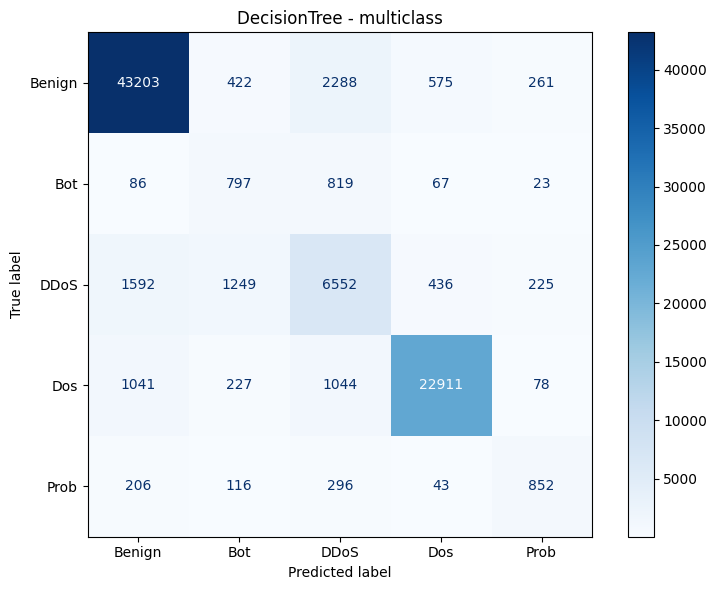

Saved: ..\reports\figures\cm_DecisionTree_multiclass.png


In [19]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

models = [
    (lr_bin, "LogisticRegression", "binary", y_test_bin),
    (lr_multi, "LogisticRegression", "multiclass", y_test_multi),
    (dt_bin, "DecisionTree", "binary", y_test_bin),
    (dt_multi_final, "DecisionTree", "multiclass", y_test_multi)
]

for model, name, task, y_true in models:
    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        model.predict(X_test),
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"{name} - {task}")
    plt.tight_layout()

    path = figures_dir / f"cm_{name}_{task}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print(f"Saved: {path}")


In [20]:
dt_multi = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

row_dt_baseline = evaluate(
    dt_multi,
    "DecisionTree",
    "multiclass",
    X_train, y_train_multi, X_test, y_test_multi
)

result.append(row_dt_baseline)
row_dt_baseline

=== DecisionTree | multiclass ===
              precision    recall  f1-score   support

      Benign     0.9169    0.9179    0.9174     46749
         Bot     0.2851    0.2924    0.2887      1792
        DDoS     0.5566    0.5501    0.5533     10054
         Dos     0.9079    0.9098    0.9088     25301
        Prob     0.5115    0.5003    0.5058      1513

    accuracy                         0.8517     85409
   macro avg     0.6356    0.6341    0.6348     85409
weighted avg     0.8514    0.8517    0.8515     85409



{'model': 'DecisionTree',
 'task': 'multiclass',
 'imbalance': 'none',
 'macro_f1': 0.63482973412692,
 'accuracy': 0.8516901029165544,
 'train_time_s': 8.57,
 'predict_ms_per_flow': 0.00037,
 'notes': ''}

In [21]:
results_df = pd.DataFrame(result)

results_df = results_df.drop_duplicates(
    subset=["model", "task", "imbalance"],
    keep="last"
)

results_df.to_csv(
    "../reports/results_baseline.csv",
    index=False
)

display(results_df)

,model,task,imbalance,macro_f1,accuracy,train_time_s,predict_ms_per_flow,notes
0,LogisticRegression,binary,none,0.911225,0.911309,12.22,0.00040,
1,LogisticRegression,multiclass,none,0.569311,0.850554,28.50,0.00052,
2,DecisionTree,binary,none,0.910251,0.911063,9.26,0.00038,
3,DecisionTree,multiclass,custom_class_weight,0.681024,0.870107,8.03,0.00030,Optimized with RandomizedSearchCV
4,DecisionTree,multiclass,none,0.634830,0.851690,8.57,0.00037,


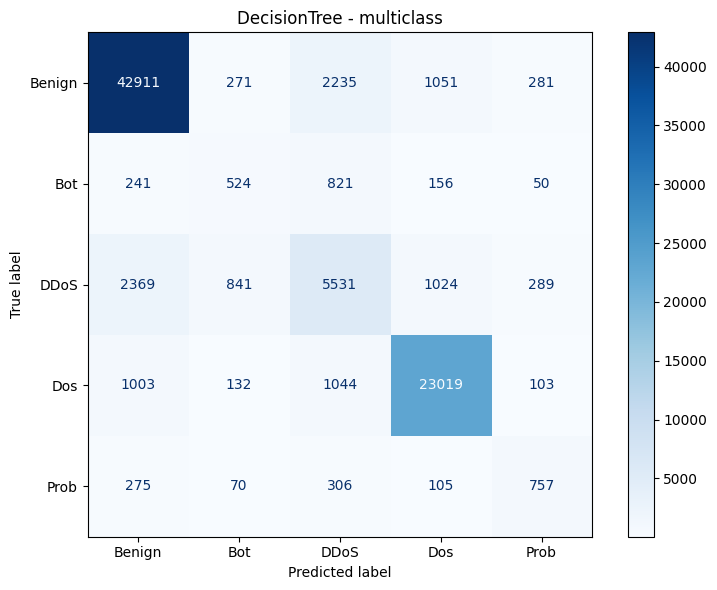

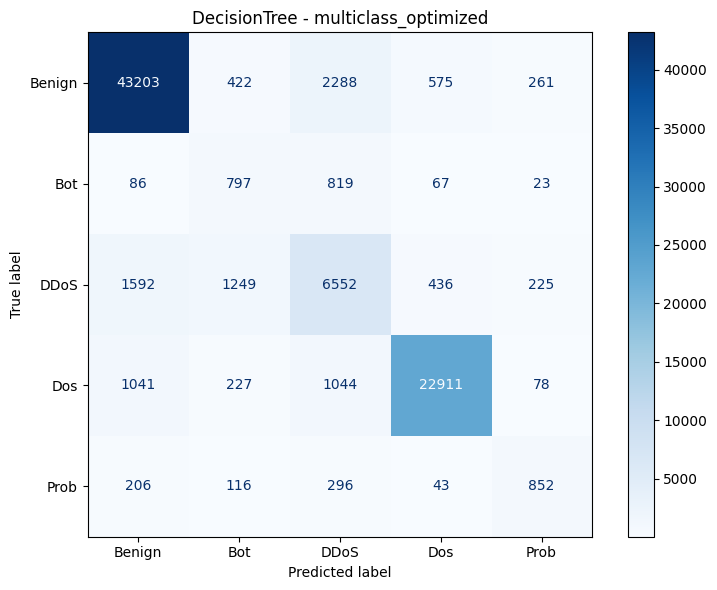

In [22]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

for model, suffix in [
    (dt_multi, "multiclass"),
    (dt_multi_final, "multiclass_optimized")
]:
    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test_multi,
        model.predict(X_test),
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"DecisionTree - {suffix}")
    plt.tight_layout()

    fig.savefig(
        figures_dir / f"cm_DecisionTree_{suffix}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

In [23]:
display(pd.read_csv("../reports/results_baseline.csv"))

for path in sorted(figures_dir.glob("cm_*.png")):
    print(path.name)

,model,task,imbalance,macro_f1,accuracy,train_time_s,predict_ms_per_flow,notes
0,LogisticRegression,binary,none,0.911225,0.911309,12.22,0.00040,NaN
1,LogisticRegression,multiclass,none,0.569311,0.850554,28.50,0.00052,NaN
2,DecisionTree,binary,none,0.910251,0.911063,9.26,0.00038,NaN
3,DecisionTree,multiclass,custom_class_weight,0.681024,0.870107,8.03,0.00030,Optimized with RandomizedSearchCV
4,DecisionTree,multiclass,none,0.634830,0.851690,8.57,0.00037,NaN


cm_DecisionTree_binary.png
cm_DecisionTree_multiclass.png
cm_DecisionTree_multiclass_optimized.png
cm_LogisticRegression_binary.png
cm_LogisticRegression_multiclass.png
